# Autoencoder: Eliminación de ruido
A partir del código suministrado, añadiremos ruido gaussiano a las imágenes de entrada. Entrenaremos un autoencoder para eliminar este ruido de las imágenes y las compararemos con las originales.

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

In [3]:
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5), (0.5))
    ])

mnist_data = datasets.MNIST(root='./data', train=True, download=True, transform=transform)

data_loader = torch.utils.data.DataLoader(dataset=mnist_data,
                                          batch_size=64,
                                          shuffle=True)

mnist_data_valid = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

data_loader_valid = torch.utils.data.DataLoader(dataset=mnist_data_valid,
                                          batch_size=64,
                                          shuffle=True)            

In [4]:
dataiter = iter(data_loader)
images, labels = next(dataiter)
print(torch.min(images), torch.max(images))

tensor(-1.) tensor(1.)


In [5]:
def add_noise(inputs, noise_factor=0.3):
    noise = torch.randn_like(inputs) * noise_factor
    noisy_inputs = inputs + noise
    noisy_inputs = torch.clamp(noisy_inputs, -1.0, 1.0)

    return noisy_inputs    

In [6]:
class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()        
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, 3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 32, 3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, 7)
        )
        
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 7),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 16, 3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(16, 1, 3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

In [7]:
model = Autoencoder()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(),
                             lr=1e-3, 
                             weight_decay=1e-5)

In [8]:
num_epochs = 10
for epoch in range(num_epochs):
    for data in data_loader:
        img, _ = data

        noisy_img = add_noise(img, noise_factor=0.3) 
        
        recon = model(noisy_img)
        
        loss = criterion(recon, img)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
    print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}')

Epoch [1/10], Loss: 0.9251
Epoch [2/10], Loss: 0.9220
Epoch [3/10], Loss: 0.9230
Epoch [4/10], Loss: 0.9210
Epoch [5/10], Loss: 0.8604
Epoch [6/10], Loss: 0.8335
Epoch [7/10], Loss: 0.8311
Epoch [8/10], Loss: 0.8451
Epoch [9/10], Loss: 0.8465
Epoch [10/10], Loss: 0.8625


In [12]:
import matplotlib.pyplot as plt
import torch

def plot_denoising_results(model, dataloader, num_images=6, noise_factor=0.5):
    clean_imgs, _ = next(iter(dataloader))
    clean_imgs = clean_imgs[:num_images]
    noisy_imgs = add_noise(clean_imgs, noise_factor=noise_factor)

    model.eval()
    with torch.no_grad():
        recon_imgs = model(noisy_imgs)

    n = len(clean_imgs)
    _, axes = plt.subplots(3, n, figsize=(n * 2, 6), squeeze=False)

    for i in range(n):
        images = [clean_imgs[i], noisy_imgs[i], recon_imgs[i]]
        titles = ["Original", "Con Ruido", "Reconstrucción"]

        for row, (image, title) in enumerate(zip(images, titles)):
            axes[row, i].imshow(image.squeeze().cpu().numpy(), cmap="gray")
            axes[row, i].set_title(title)
            axes[row, i].axis("off")

    plt.tight_layout()
    plt.show()

## Comprobación con distintos factores de ruido
- `noise_factor` = **0.5**

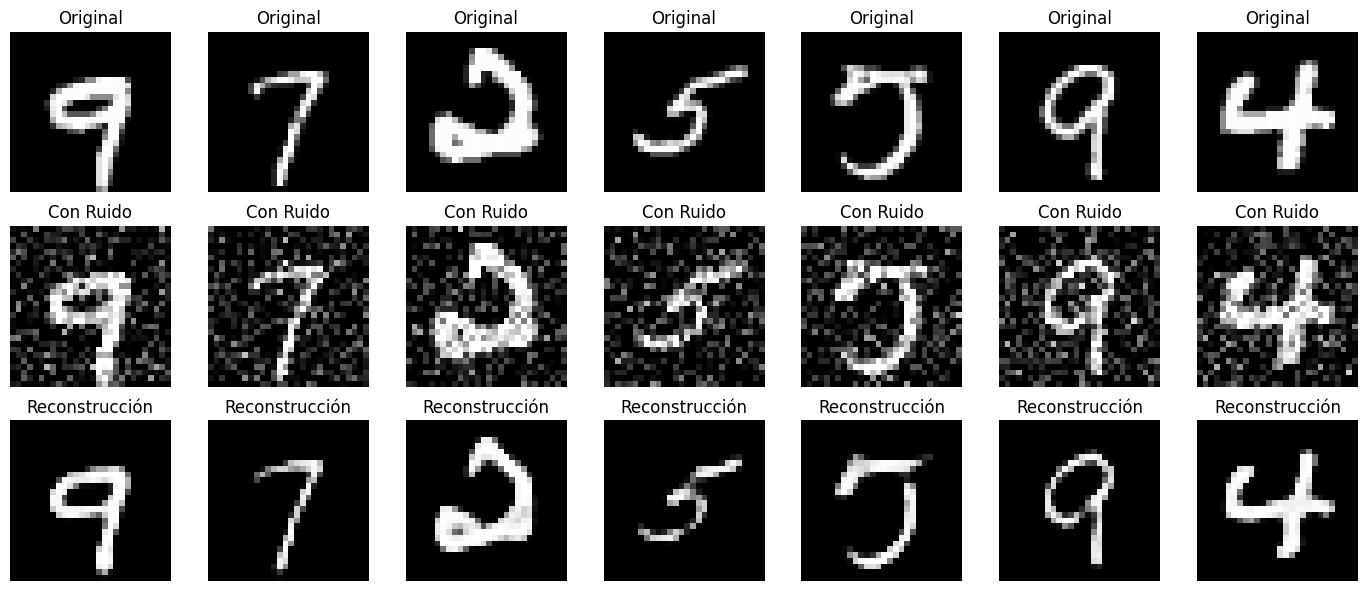

In [13]:
plot_denoising_results(model, data_loader_valid, num_images=7, noise_factor=0.5)

- `noise_factor` = **0.9**

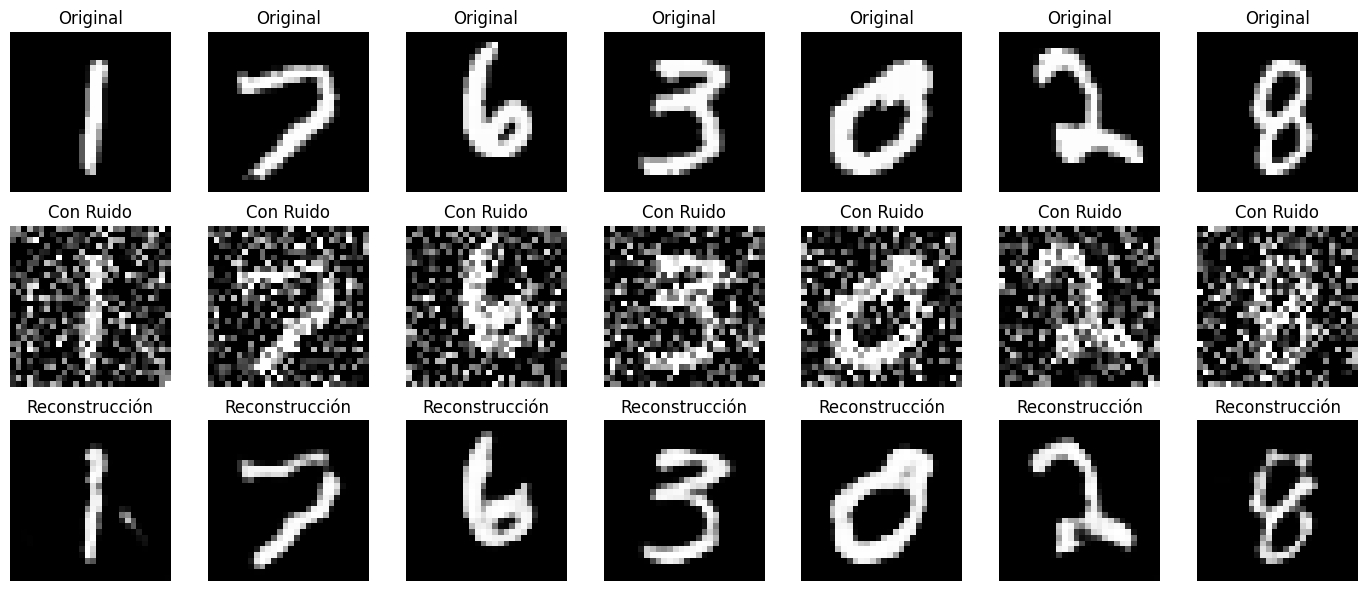

In [14]:
plot_denoising_results(model, data_loader_valid, num_images=7, noise_factor=0.9)